In [84]:
from pathlib import Path
import pandas as pd

dataset_root = Path(r"C:\Users\barta\Documents\cours\ML_IMT\CI3\HUMAPS\HUMAPS")

def load_folder_data(folder_path: Path, sep: str = ";") -> pd.DataFrame:
    dfs = []
    for csv_path in sorted(folder_path.rglob("*.csv")):
        df = pd.read_csv(csv_path, sep=sep)
        
        # Nettoie les espaces éventuels et corrige la typo d'en-tête "2Name" -> "Name"
        df.columns = df.columns.str.strip()
        if "2Name" in df.columns:
            df = df.rename(columns={"2Name": "Name"})

        # Ajoute patient et sequence (sans écraser s'ils existent déjà)
        if "patient" not in df.columns:
            df["patient"] = csv_path.parents[1].name   # ex: "S1"
        if "sequence" not in df.columns:
            df["sequence"] = csv_path.parent.name      # ex: "sequence_01"
            
        dfs.append(df)

    if not dfs:
        raise FileNotFoundError(f"Aucun fichier CSV trouvé dans {folder_path}")

    return pd.concat(dfs, ignore_index=True)

events = load_folder_data(dataset_root / "Events")
pressure = load_folder_data(dataset_root / "Pressure")

print("Events :", events.shape)
print(events.head())

print("\nPressure :", pressure.shape)
print(pressure.head())


Events : (10204, 8)
                  Name  Class  Frame Start  Timestamp Start  Frame End  \
0   Standing in T-pose    1.0        984.0          8.19167     1572.0   
1    Standing on heels    7.0       1572.0         13.09167     2022.0   
2    Walking backwards   10.0       2022.0         16.84167     2595.0   
3  Climbing the stairs   21.0       2595.0         21.61667     3072.0   
4  Standing on tiptoes    6.0       3072.0         25.59167     3666.0   

   Timestamp End patient     sequence  
0       13.09167     S01  Sequence_01  
1       16.84167     S01  Sequence_01  
2       21.61667     S01  Sequence_01  
3       25.59167     S01  Sequence_01  
4       30.54167     S01  Sequence_01  

Pressure : (4749976, 53)
   Time  left pressure 1[N/cm²]  left pressure 2[N/cm²]  \
0  0.00                    4.25                    1.75   
1  0.01                    4.25                    1.75   
2  0.02                    3.75                    1.75   
3  0.03                    3.75  

In [85]:
pressure.head()

,Time,left pressure 1[N/cm²],left pressure 2[N/cm²],left pressure 3[N/cm²],left pressure 4[N/cm²],left pressure 5[N/cm²],left pressure 6[N/cm²],left pressure 7[N/cm²],left pressure 8[N/cm²],left pressure 9[N/cm²],...,right acceleration Y[g],right acceleration Z[g],right angular X[dps],right angular Y[dps],right angular Z[dps],right total force[N],right center of pressure X[-0.5...+0.5],right center of pressure Y[-0.5...+0.5],patient,sequence
0,0.00,4.25,1.75,4.00,2.25,2.75,3.5,0.5,2.75,3.25,...,0.037109,0.977051,-1.89,-1.19,0.70,542.0,-0.200511,-0.154638,S01,Sequence_01
1,0.01,4.25,1.75,4.00,2.25,2.75,3.5,0.5,2.50,3.25,...,0.037109,0.977051,-1.89,-1.19,0.70,542.0,-0.200511,-0.154638,S01,Sequence_01
2,0.02,3.75,1.75,4.00,2.25,2.75,3.5,0.5,2.50,3.50,...,0.037109,0.977051,-1.89,-1.19,0.70,542.0,-0.200511,-0.154638,S01,Sequence_01
3,0.03,3.75,1.75,3.25,2.00,3.00,3.5,0.5,2.50,3.50,...,0.040527,0.979004,-1.82,-1.05,0.56,544.0,-0.201996,-0.152734,S01,Sequence_01
4,0.04,4.25,1.75,4.00,2.00,3.00,3.5,0.5,2.75,3.50,...,0.039551,0.978516,-2.03,-0.98,0.42,539.0,-0.207568,-0.145954,S01,Sequence_01


In [86]:
pressure.columns

Index(['Time', 'left pressure 1[N/cm²]', 'left pressure 2[N/cm²]',
       'left pressure 3[N/cm²]', 'left pressure 4[N/cm²]',
       'left pressure 5[N/cm²]', 'left pressure 6[N/cm²]',
       'left pressure 7[N/cm²]', 'left pressure 8[N/cm²]',
       'left pressure 9[N/cm²]', 'left pressure 10[N/cm²]',
       'left pressure 11[N/cm²]', 'left pressure 12[N/cm²]',
       'left pressure 13[N/cm²]', 'left pressure 14[N/cm²]',
       'left pressure 15[N/cm²]', 'left pressure 16[N/cm²]',
       'left acceleration X[g]', 'left acceleration Y[g]',
       'left acceleration Z[g]', 'left angular X[dps]', 'left angular Y[dps]',
       'left angular Z[dps]', 'left total force[N]',
       'left center of pressure X[-0.5...+0.5]',
       'left center of pressure Y[-0.5...+0.5]', 'right pressure 1[N/cm²]',
       'right pressure 2[N/cm²]', 'right pressure 3[N/cm²]',
       'right pressure 4[N/cm²]', 'right pressure 5[N/cm²]',
       'right pressure 6[N/cm²]', 'right pressure 7[N/cm²]',
       'right 

In [87]:
events.head()

,Name,Class,Frame Start,Timestamp Start,Frame End,Timestamp End,patient,sequence
0,Standing in T-pose,1.0,984.0,8.19167,1572.0,13.09167,S01,Sequence_01
1,Standing on heels,7.0,1572.0,13.09167,2022.0,16.84167,S01,Sequence_01
2,Walking backwards,10.0,2022.0,16.84167,2595.0,21.61667,S01,Sequence_01
3,Climbing the stairs,21.0,2595.0,21.61667,3072.0,25.59167,S01,Sequence_01
4,Standing on tiptoes,6.0,3072.0,25.59167,3666.0,30.54167,S01,Sequence_01


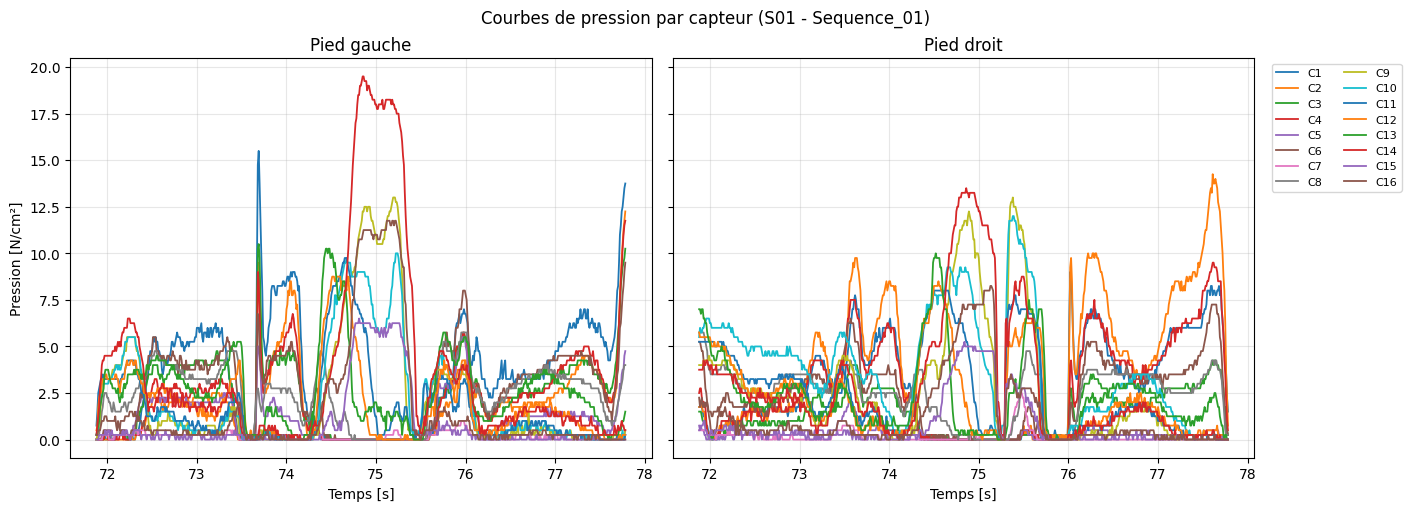

In [88]:
x_axis = sample[time_col] if time_col is not None else sample.index
x_label = "Temps [s]" if time_col is not None else "Index de mesure"

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True, constrained_layout=True)

for ax, side, title in zip(axes, ["left", "right"], ["Pied gauche", "Pied droit"]):
    for sensor_id in range(1, 17):
        col = f"{side} pressure {sensor_id}[N/cm²]"
        ax.plot(x_axis, sample[col], label=f"C{sensor_id}", linewidth=1.3)
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Pression [N/cm²]")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize=8)
plt.suptitle(f"Courbes de pression par capteur ({p0} - {s0})")
plt.show()

## une seule séquence possede plusieurs mouvements qu'il  faut alors découper

In [89]:
import numpy as np
import pandas as pd

# Initialise la colonne cible (NaN pour les instants hors mouvement)
pressure['Class'] = np.nan

ev_groups = events.groupby(['patient', 'sequence'])

for keys, df_p in pressure.groupby(['patient', 'sequence']):
  if keys not in ev_groups.groups:
    continue

  df_e = ev_groups.get_group(keys)

  for start, end, cls in zip(
      df_e['Timestamp Start'], df_e['Timestamp End'], df_e['Class']
  ):
    mask = (df_p['Time'] >= start) & (df_p['Time'] <= end)
    pressure.loc[df_p.index[mask], 'Class'] = cls
print(df_e.head())
print(pressure.head())
print(events.head())

                                Name  Class  Frame Start  Timestamp Start  \
10172             Standing in T-pose    1.0        462.0          3.84167   
10173        Jumping on the left leg   16.0       1009.0          8.40000   
10174                        Walking    8.0       1408.0         11.72500   
10175  Lifting the bag with one hand   22.0       2133.0         17.76667   
10176    Balancing on the right leg     4.0       2874.0         23.94167   

       Frame End  Timestamp End patient     sequence  
10172     1009.0        8.40000     S32  Sequence_10  
10173     1408.0       11.72500     S32  Sequence_10  
10174     2133.0       17.76667     S32  Sequence_10  
10175     2874.0       23.94167     S32  Sequence_10  
10176     3219.0       26.81667     S32  Sequence_10  
   Time  left pressure 1[N/cm²]  left pressure 2[N/cm²]  \
0  0.00                    4.25                    1.75   
1  0.01                    4.25                    1.75   
2  0.02                    3.7

In [90]:
print('Dtypes pressure :', pressure[['patient', 'sequence', 'Time']].dtypes)
print(
    'Dtypes events   :',
    events[['patient', 'sequence', 'Timestamp Start', 'Timestamp End']].dtypes,
)

p_keys = set(zip(pressure['patient'], pressure['sequence']))
e_keys = set(zip(events['patient'], events['sequence']))
print('Paires communes :', len(p_keys & e_keys), '/', len(e_keys))

print(
    'Plage Time      :', pressure['Time'].min(), '->', pressure['Time'].max()
)
print(
    'Plage Events    :',
    events['Timestamp Start'].min(),
    '->',
    events['Timestamp End'].max(),
)

Dtypes pressure : patient         str
sequence        str
Time        float64
dtype: object
Dtypes events   : patient                str
sequence               str
Timestamp Start    float64
Timestamp End      float64
dtype: object
Paires communes : 319 / 319
Plage Time      : 0.0 -> 172.39
Plage Events    : 0.0 -> 172.17769


In [91]:
import numpy as np
import pandas as pd

# 1. Harmonise les types des clés et des colonnes temporelles
for df in (pressure, events):
  df['patient'] = df['patient'].astype(str).str.strip()
  df['sequence'] = df['sequence'].astype(str).str.strip()

pressure['Time'] = pd.to_numeric(
    pressure['Time'].astype(str).str.replace(',', '.'), errors='coerce'
)
for col in ('Timestamp Start', 'Timestamp End'):
  events[col] = pd.to_numeric(
      events[col].astype(str).str.replace(',', '.'), errors='coerce'
  )

# 2. Découpage par groupe et alignement à l'indice le plus proche
pressure['Class'] = np.nan
ev_groups = events.groupby(['patient', 'sequence'])

for keys, df_p in pressure.groupby(['patient', 'sequence']):
  if keys not in ev_groups.groups:
    continue

  df_e = ev_groups.get_group(keys)
  times = df_p['Time'].to_numpy()
  t_min, t_max = times.min(), times.max()

  for start, end, cls in zip(
      df_e['Timestamp Start'], df_e['Timestamp End'], df_e['Class']
  ):
    # Ignore l'événement s'il est totalement en dehors de la séquence
    if end < t_min or start > t_max:
      continue

    i_start = np.abs(times - start).argmin()
    i_end = np.abs(times - end).argmin()
    lo, hi = min(i_start, i_end), max(i_start, i_end)

    pressure.loc[df_p.index[lo : hi + 1], 'Class'] = cls


In [92]:
pressure.isna().sum()/len(pressure)

Time                                       0.000000
left pressure 1[N/cm²]                     0.000000
left pressure 2[N/cm²]                     0.000000
left pressure 3[N/cm²]                     0.000000
left pressure 4[N/cm²]                     0.000000
left pressure 5[N/cm²]                     0.000000
left pressure 6[N/cm²]                     0.000000
left pressure 7[N/cm²]                     0.000000
left pressure 8[N/cm²]                     0.000000
left pressure 9[N/cm²]                     0.000000
left pressure 10[N/cm²]                    0.000000
left pressure 11[N/cm²]                    0.000000
left pressure 12[N/cm²]                    0.000000
left pressure 13[N/cm²]                    0.000000
left pressure 14[N/cm²]                    0.000000
left pressure 15[N/cm²]                    0.000000
left pressure 16[N/cm²]                    0.000000
left acceleration X[g]                     0.000000
left acceleration Y[g]                     0.000000
left acceler

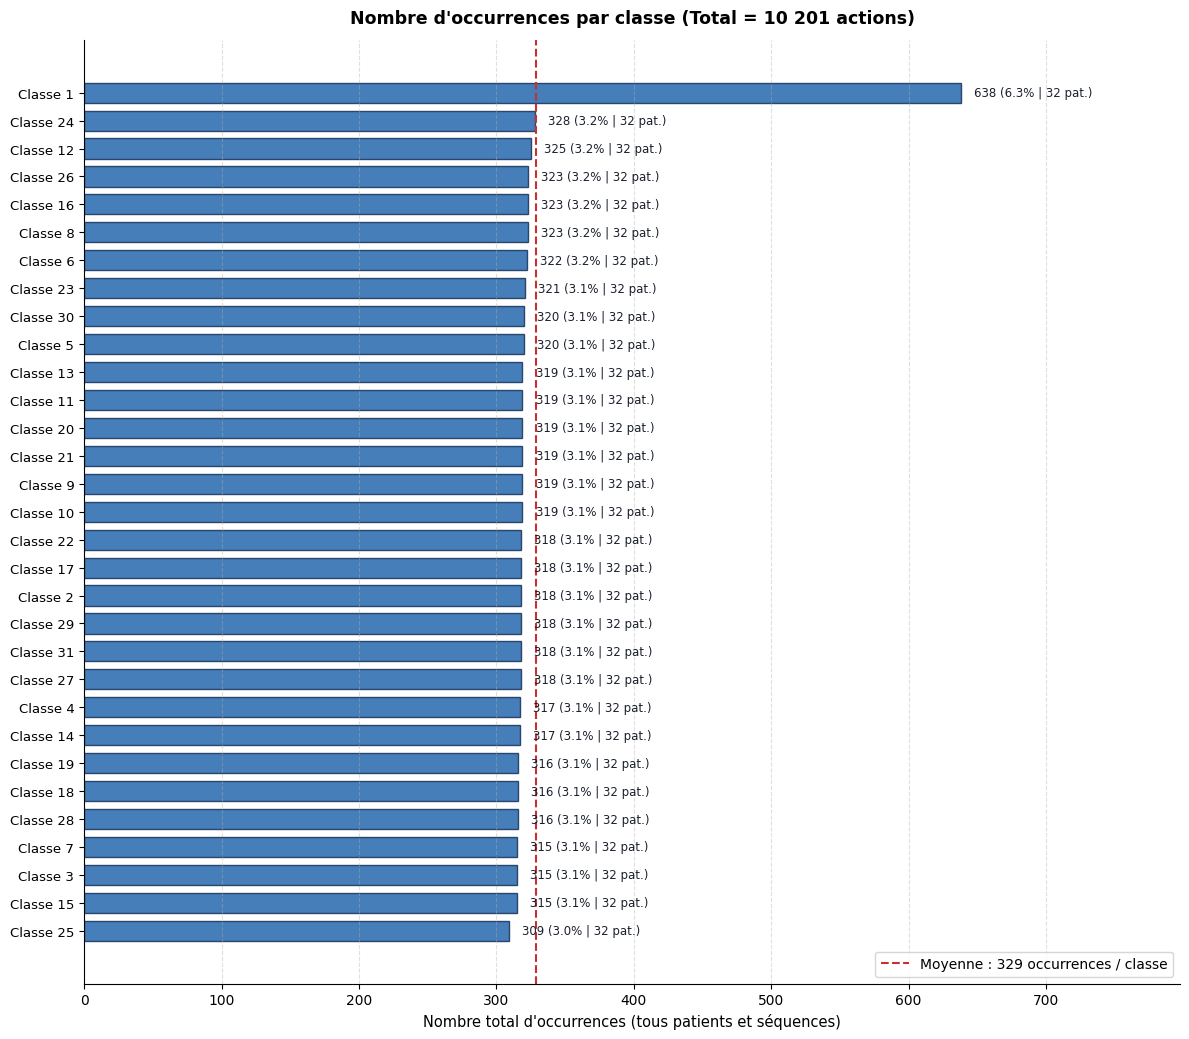

In [93]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Extraction légère (4 colonnes uniquement pour éviter tout MemoryError)
df_meta = pressure[["patient", "sequence", "Time", "Class"]].sort_values(
    ["patient", "sequence", "Time"]
)

# 2. Identification de chaque occurrence contiguë d'action
new_action = (
    (df_meta["patient"] != df_meta["patient"].shift())
    | (df_meta["sequence"] != df_meta["sequence"].shift())
    | (
        df_meta["Class"].fillna("__NONE__")
        != df_meta["Class"].fillna("__NONE__").shift()
    )
)
df_meta["action_id"] = new_action.cumsum()

# 3. Comptage des occurrences uniques par Classe (hors périodes NaN)
occurrences = (
    df_meta.dropna(subset=["Class"])
    .groupby("action_id", as_index=False)
    .agg(
        Class=("Class", "first"),
        patient=("patient", "first"),
    )
)

def format_class_label(x):
    try:
        val = float(x)
        return f"Classe {int(val)}" if val.is_integer() else f"Classe {x}"
    except (ValueError, TypeError):
        return str(x)

occurrences["Class_label"] = occurrences["Class"].apply(format_class_label)

# Agrégation : nombre total d'occurrences et nombre de patients distincts
counts = (
    occurrences.groupby("Class_label")
    .agg(
        nb_occurrences=("action_id", "count"),
        nb_patients=("patient", "nunique"),
    )
    .sort_values("nb_occurrences", ascending=True)  # Plus fréquente en haut
)

total_occ = counts["nb_occurrences"].sum()
mean_occ = counts["nb_occurrences"].mean()
counts["part_pct"] = 100 * counts["nb_occurrences"] / total_occ

# 4. Graphique en barres horizontales
fig, ax = plt.subplots(figsize=(12, 10.5))

y_pos = np.arange(len(counts))
bars = ax.barh(
    y_pos,
    counts["nb_occurrences"],
    height=0.72,
    color="#2b6cb0",
    edgecolor="#1a365d",
    alpha=0.88,
)

# Repère visuel de la moyenne
ax.axvline(
    mean_occ,
    color="#c53030",
    linestyle="--",
    linewidth=1.5,
    label=f"Moyenne : {mean_occ:.0f} occurrences / classe",
)

ax.set_yticks(y_pos)
ax.set_yticklabels(counts.index, fontsize=9.5)
ax.set_xlabel("Nombre total d'occurrences (tous patients et séquences)", fontsize=10.5)
ax.set_title(
    f"Nombre d'occurrences par classe (Total = {total_occ:,} actions)".replace(",", " "),
    fontsize=12.5,
    fontweight="bold",
    pad=12,
)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", fontsize=10)

max_val = counts["nb_occurrences"].max()
ax.set_xlim(0, max_val * 1.25)

for bar, (_, row) in zip(bars, counts.iterrows()):
    val = int(row["nb_occurrences"])
    pct = row["part_pct"]
    n_pat = int(row["nb_patients"])
    ax.text(
        val + max_val * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{val} ({pct:.1f}% | {n_pat} pat.)",
        va="center",
        ha="left",
        fontsize=8.5,
        color="#1a202c",
    )

plt.tight_layout()
plt.show()

## Class 1 est la T pose, qui apparait au début et a la fin de chaque video

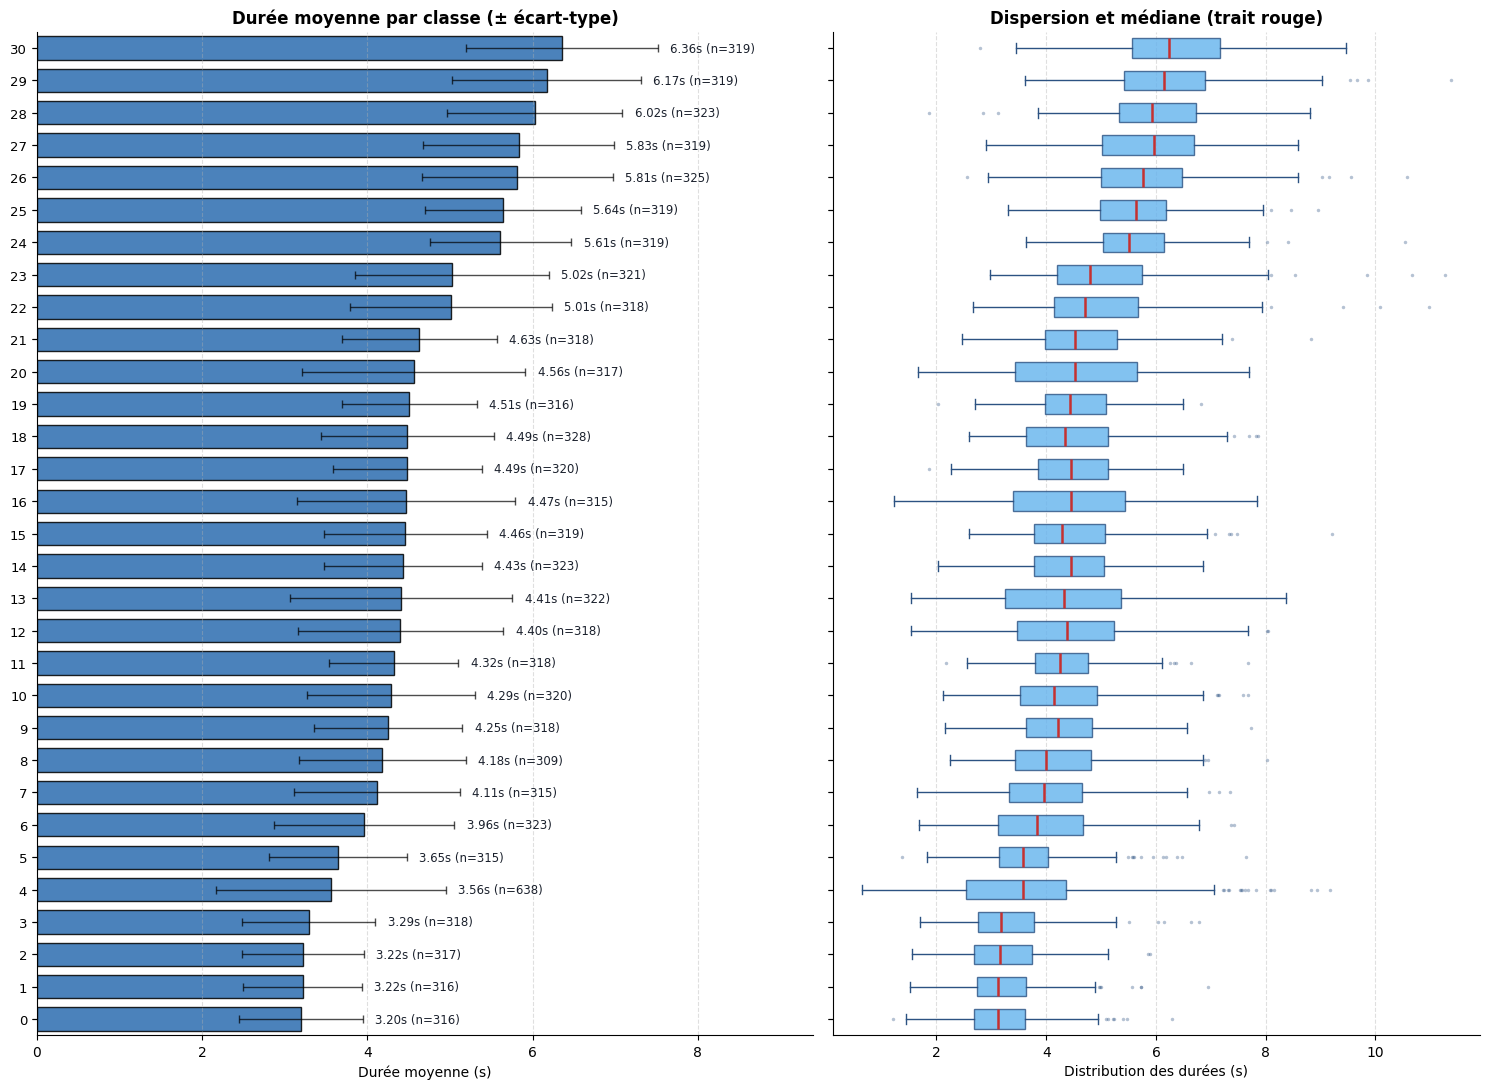

In [94]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Nettoyage de l'affichage des numéros de classe (ex: 10.0 -> "10")
durations['Class_label'] = durations['Class'].apply(
    lambda x: str(int(x)) if float(x).is_integer() else str(x)
)

# Recalcul des statistiques triées par moyenne croissante (pour avoir la plus grande en haut)
stats = (
    durations.groupby('Class_label')['duration']
    .agg(
        nb_occurrences='count',
        moyenne='mean',
        ecart_type='std',
        mediane='median',
    )
    .sort_values('moyenne', ascending=True)
)

order = stats.index.tolist()
y_pos = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(15, 11),
    sharey=True,
    gridspec_kw={'width_ratios': [1.2, 1]},
)

# --- Panneau gauche : Durée moyenne ± écart-type ---
stds = stats['ecart_type'].fillna(0)
bars = ax1.barh(
    y_pos,
    stats['moyenne'],
    xerr=stds,
    height=0.72,
    capsize=3,
    color='#2b6cb0',
    edgecolor='black',
    alpha=0.85,
    error_kw={'elinewidth': 1, 'alpha': 0.7},
)

ax1.set_yticks(y_pos)
ax1.set_yticklabels([f'Classe {c}' for c in order], fontsize=9.5)
ax1.set_xlabel('Durée moyenne (s)', fontsize=10)
ax1.set_title(
    'Durée moyenne par classe (± écart-type)', fontsize=12, fontweight='bold'
)
ax1.grid(axis='x', linestyle='--', alpha=0.4)
ax1.spines[['top', 'right']].set_visible(False)

# Ajoute une marge à droite pour que le texte ne dépasse pas du cadre
max_x = (stats['moyenne'] + stds).max()
ax1.set_xlim(0, max_x * 1.25)

for bar, (_, row), std in zip(bars, stats.iterrows(), stds):
  x_text = row['moyenne'] + std + (max_x * 0.02)
  ax1.text(
      x_text,
      bar.get_y() + bar.get_height() / 2,
      f"{row['moyenne']:.2f}s (n={int(row['nb_occurrences'])})",
      va='center',
      ha='left',
      fontsize=8.5,
      color='#1a202c',
  )

# --- Panneau droit : Distribution détaillée par classe (Boxplot) ---
box_data = [
    durations.loc[durations['Class_label'] == c, 'duration'].values
    for c in order
]

bp = ax2.boxplot(
    box_data,
    positions=y_pos,
    vert=False,
    widths=0.6,
    patch_artist=True,
    boxprops=dict(facecolor='#63b3ed', edgecolor='#2c5282', alpha=0.8),
    medianprops=dict(color='#c53030', linewidth=1.8),
    whiskerprops=dict(color='#2c5282', linewidth=1),
    capprops=dict(color='#2c5282', linewidth=1),
    flierprops=dict(
        marker='o',
        markersize=2.5,
        alpha=0.35,
        markerfacecolor='#2c5282',
        markeredgecolor='none',
    ),
)

ax2.set_xlabel('Distribution des durées (s)', fontsize=10)
ax2.set_title(
    'Dispersion et médiane (trait rouge)', fontsize=12, fontweight='bold'
)
ax2.grid(axis='x', linestyle='--', alpha=0.4)
ax2.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

corriger nom colonne

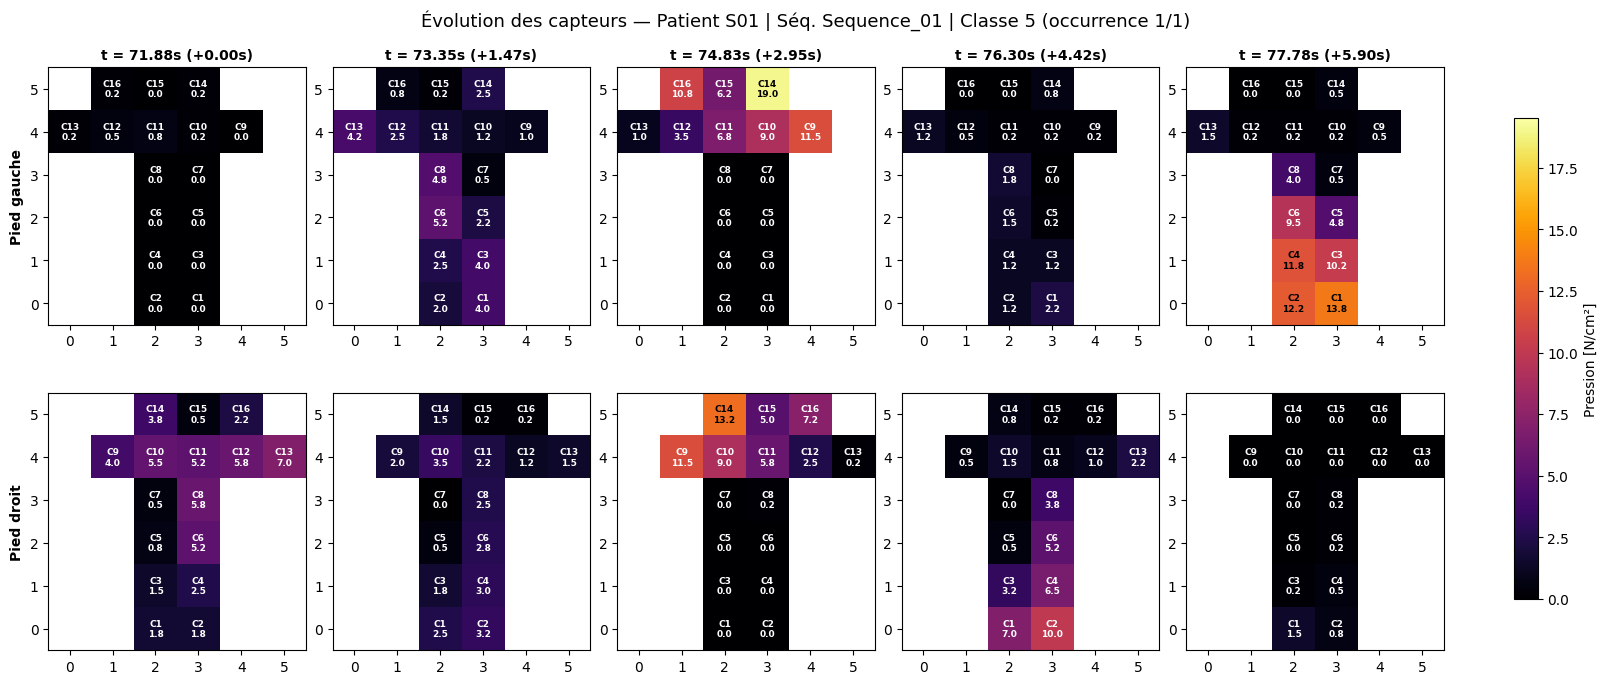

In [95]:
import matplotlib.pyplot as plt
import numpy as np

# Liste de listes : index (sensor_id - 1) -> [ligne, colonne] dans la matrice 6x6
SENSOR_POSITIONS = [
    [0, 3], [0, 2],                          # Capteurs 1, 2
    [1, 3], [1, 2],                          # Capteurs 3, 4
    [2, 3], [2, 2],                          # Capteurs 5, 6
    [3, 3], [3, 2],                          # Capteurs 7, 8
    [4, 4], [4, 3], [4, 2], [4, 1], [4, 0],  # Capteurs 9 à 13
    [5, 3], [5, 2], [5, 1],                  # Capteurs 14, 15, 16
]

# Version miroir (pied droit) calculée automatiquement : [ligne, 5 - colonne]
SENSOR_POSITIONS_MIRROR = [[r, 5 - c] for r, c in SENSOR_POSITIONS]


def build_foot_matrix(row_or_series, side: str = "left", mirror: bool = False) -> np.ndarray:
    """Remplit la matrice 6x6 directement depuis la liste des positions."""
    grid = np.full((6, 6), np.nan, dtype=float)
    positions = SENSOR_POSITIONS_MIRROR if mirror else SENSOR_POSITIONS

    for sensor_id, (r, c) in enumerate(positions, start=1):
        col_name = f"{side} pressure {sensor_id}[N/cm²]"
        grid[r, c] = row_or_series[col_name]

    return grid


# --- 1. Sélection légère SANS copier les 52 colonnes de pressure ---
meta = pressure[["patient", "sequence", "Class"]].dropna(subset=["Class"])

# Choisis directement le numéro de la classe voulue (ex: 5, 12, 20...)
TARGET_CLASS = 5
occurrence_idx = 0  # 0 = 1re exécution de cette classe dans la séquence

# Filtre d'abord sur la classe pour garantir que (p0, s0) la contient bien
meta_cls = meta[meta["Class"] == TARGET_CLASS]
if meta_cls.empty:
    dispo = sorted(meta["Class"].unique())
    raise ValueError(f"Classe {TARGET_CLASS} introuvable. Classes disponibles : {dispo}")

# Prend le 1er patient/séquence réalisant cette classe (ou change iloc[0] par iloc[1], etc.)
p0 = meta_cls["patient"].iloc[0]
s0 = meta_cls["sequence"].iloc[0]
c0 = TARGET_CLASS

# Extrait uniquement la séquence voulue
mask_seq = (pressure["patient"] == p0) & (pressure["sequence"] == s0)
seq_df = pressure.loc[mask_seq].copy()

seq_df["action_block"] = (
    seq_df["Class"].fillna("__NONE__") != seq_df["Class"].fillna("__NONE__").shift()
).cumsum()

class_blocks = [
    grp for _, grp in seq_df[seq_df["Class"] == c0].groupby("action_block")
]
sample = class_blocks[occurrence_idx].reset_index(drop=True)

# --- 2. Sélection de N instants régulièrement espacés dans l'action ---
n_steps = min(5, len(sample))  # S'adapte si l'action contient moins de 5 échantillons
indices = np.linspace(0, len(sample) - 1, n_steps, dtype=int)

# Détection automatique de la colonne de temps (inclut "Time" avec majuscule)
time_col = next((c for c in ["Time", "time", "timestamp", "t"] if c in sample.columns), None)

# Échelle de couleur globale sur toute l'action (pour comparer les instants entre eux)
sensor_cols = [
    f"{side} pressure {i}[N/cm²]"
    for side in ("left", "right")
    for i in range(1, 17)
]
vmax = sample[sensor_cols].max().max()

# --- 3. Affichage de l'évolution temporelle (2 lignes x n_steps colonnes) ---
fig, axes = plt.subplots(
    2, n_steps,
    figsize=(3.2 * n_steps, 6.8),
    constrained_layout=True,
    squeeze=False
)

t0 = sample[time_col].iloc[0] if time_col is not None else 0.0

for col_idx, row_idx in enumerate(indices):
    row = sample.iloc[row_idx]
    if time_col is not None:
        dt_rel = row[time_col] - t0
        time_label = f"t = {row[time_col]:.2f}s (+{dt_rel:.2f}s)"
    else:
        time_label = f"Mesure {row_idx + 1}/{len(sample)}"

    for row_plot, (side, side_label, mirror) in enumerate([
        ("left", "Pied gauche", False),
        ("right", "Pied droit", True),
    ]):
        ax = axes[row_plot, col_idx]
        grid = build_foot_matrix(row, side=side, mirror=mirror)

        im = ax.imshow(grid, cmap="inferno", vmin=0, vmax=vmax, origin="lower")
        ax.set_xticks(range(6))
        ax.set_yticks(range(6))

        if row_plot == 0:
            ax.set_title(time_label, fontsize=10, fontweight="bold")
        if col_idx == 0:
            ax.set_ylabel(side_label, fontsize=10, fontweight="bold")

        positions = SENSOR_POSITIONS_MIRROR if mirror else SENSOR_POSITIONS
        for sensor_id, (r, c) in enumerate(positions, start=1):
            val = grid[r, c]
            ax.text(
                c, r,
                f"C{sensor_id}\n{val:.1f}",
                ha="center", va="center",
                color="white" if val < vmax * 0.6 else "black",
                fontsize=6.5, fontweight="bold"
            )

class_str = str(int(c0)) if isinstance(c0, float) and c0.is_integer() else str(c0)
fig.colorbar(im, ax=axes, label="Pression [N/cm²]", shrink=0.75)
plt.suptitle(
    f"Évolution des capteurs — Patient {p0} | Séq. {s0} | Classe {class_str} "
    f"(occurrence {occurrence_idx + 1}/{len(class_blocks)})",
    fontsize=13
)
plt.show()

In [96]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    f1_score,
    classification_report,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# ==============================================================================
# 1. REPRODUCTIBILITÉ
# ==============================================================================
SEED = 42

def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [97]:
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import DataLoader, TensorDataset

# ==============================================================================
# 2. CONSTRUCTION DE X (N, 32, T), y (CLASS) ET IDENTIFIANTS D'ACTION / SUJET
# ==============================================================================
cols_to_drop = [
    "patient", "sequence", "Time", "Class",
    "left acceleration X[g]", "left acceleration Y[g]", "left acceleration Z[g]",
    "left angular X[dps]", "left angular Y[dps]", "left angular Z[dps]",
    "left total force[N]",
    "left center of pressure X[-0.5...+0.5]", "left center of pressure Y[-0.5...+0.5]",
    "right acceleration X[g]", "right acceleration Y[g]", "right acceleration Z[g]",
    "right angular X[dps]", "right angular Y[dps]", "right angular Z[dps]",
    "right total force[N]",
    "right center of pressure X[-0.5...+0.5]", "right center of pressure Y[-0.5...+0.5]",
]

sensor_cols = [c for c in pressure.columns if c not in cols_to_drop]

# À dt = 0.01 s (100 Hz) : 256 échantillons = 2.56 s, stride 128 = 1.28 s (50 % recouvrement)
WINDOW_SIZE = 256
STRIDE = 128

X_windows, y_list, subj_list, action_id_list = [], [], [], []
global_action_id = 0

for (pat, _), group in pressure.groupby(["patient", "sequence"], sort=False):
    group_sorted = group.sort_values("Time")

    cls_series = group_sorted["Class"]
    block_ids = (cls_series.fillna("__NONE__") != cls_series.fillna("__NONE__").shift()).cumsum()

    for _, action_grp in group_sorted.groupby(block_ids, sort=False):
        cls = action_grp["Class"].iloc[0]
        if pd.isna(cls):
            continue

        vals = action_grp[sensor_cols].to_numpy(dtype=np.float32)  # (L, 32)

        if len(vals) < WINDOW_SIZE:
            vals = np.pad(vals, ((0, WINDOW_SIZE - len(vals)), (0, 0)), mode="edge")

        for start in range(0, len(vals) - WINDOW_SIZE + 1, STRIDE):
            X_windows.append(vals[start : start + WINDOW_SIZE].T)
            y_list.append(cls)
            subj_list.append(pat)
            action_id_list.append(global_action_id)

        global_action_id += 1

X = np.stack(X_windows, axis=0)            # (N, 32, T) en float32
y = np.asarray(y_list)                     # (N,) -> Class cible
subjects = np.asarray(subj_list)           # (N,) -> patient
action_ids = np.asarray(action_id_list)    # (N,) -> identifiant unique de chaque occurrence

le = LabelEncoder()
y_encoded = le.fit_transform(y)
action_names = list(le.classes_)
subject_names = sorted(
    np.unique(subjects),
    key=lambda s: int(str(s).replace("S", "")) if str(s).startswith("S") else str(s),
)

# ==============================================================================
# 3. SPLIT STRATIFIÉ 80 % / 20 % PAR OCCURRENCE D'ACTION ENTIÈRE (SANS COUPURE)
# ==============================================================================
# n_splits=5 -> 1 fold (20 %) pour le test, 4 folds (80 %) pour l'entraînement
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_train, idx_test = next(sgkf.split(X, y_encoded, groups=action_ids))

X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y_encoded[idx_train], y_encoded[idx_test]
subj_test = subjects[idx_test]

# Vérification qu'aucune occurrence d'action n'est partagée entre train et test
assert len(set(action_ids[idx_train]) & set(action_ids[idx_test])) == 0

# Normalisation par capteur calculée uniquement sur X_train (en float32 pour la RAM)
mean = X_train.mean(axis=(0, 2), keepdims=True)
std = X_train.std(axis=(0, 2), keepdims=True) + np.float32(1e-8)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train), torch.tensor(y_train, dtype=torch.long)),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
test_loader = DataLoader(
    TensorDataset(torch.tensor(X_test), torch.tensor(y_test, dtype=torch.long)),
    batch_size=128,
    shuffle=False,
)

In [98]:

# ==============================================================================
# 3. ARCHITECTURE CNN 1D
# ==============================================================================
class CNN1D(nn.Module):
    def __init__(self, in_channels: int = 32, num_classes: int = 30):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(in_channels, 64, kernel_size=7, padding=3, bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 128, kernel_size=5, padding=2, bias=False),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))

model = CNN1D(in_channels=X_train.shape[1], num_classes=len(action_names)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40)


In [99]:

# ==============================================================================
# 4. ENTRAÎNEMENT & PRÉDICTION
# ==============================================================================
EPOCHS = 40
best_macro_f1 = -1.0
best_preds = None

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        loss = criterion(model(bx), by)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * bx.size(0)

    scheduler.step()

    model.eval()
    preds_list = []
    with torch.no_grad():
        for bx, _ in test_loader:
            preds_list.append(model(bx.to(device)).argmax(dim=1).cpu().numpy())
    y_pred = np.concatenate(preds_list)

    macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
    if macro_f1 > best_macro_f1:
        best_macro_f1 = macro_f1
        best_preds = y_pred.copy()
        torch.save(model.state_dict(), "best_cnn1d.pt")

    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{EPOCHS} | Loss: {train_loss / len(X_train):.4f} | Test Macro-F1: {macro_f1:.4f}")

y_pred = best_preds
print(f"\n=== Meilleur Macro-F1 global (30 mouvements) : {best_macro_f1:.4f} ===\n")
print(classification_report(y_test, y_pred, target_names=[str(a) for a in action_names], digits=3, zero_division=0))



Epoch 01/40 | Loss: 2.0115 | Test Macro-F1: 0.4676
Epoch 10/40 | Loss: 1.0037 | Test Macro-F1: 0.6379
Epoch 20/40 | Loss: 0.7370 | Test Macro-F1: 0.6733
Epoch 30/40 | Loss: 0.5748 | Test Macro-F1: 0.7076
Epoch 40/40 | Loss: 0.5149 | Test Macro-F1: 0.7110

=== Meilleur Macro-F1 global (30 mouvements) : 0.7120 ===

              precision    recall  f1-score   support

         1.0      0.488     0.744     0.590       227
         2.0      0.175     0.165     0.170       127
         3.0      0.705     0.761     0.732       113
         4.0      0.726     0.695     0.710       164
         5.0      0.704     0.769     0.735       130
         6.0      0.846     0.776     0.809       134
         7.0      0.855     0.825     0.839       114
         8.0      0.858     0.950     0.901       159
         9.0      0.930     0.976     0.952       164
        10.0      0.886     0.846     0.866       240
        11.0      0.939     0.914     0.926       186
        12.0      0.890     0.796   

In [100]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

# ==============================================================================
# 5. DISTRIBUTION PAR CLASSE & TABLEAU CROISÉ SUJETS × CLASSES (P / R / F1)
# ==============================================================================
def format_cls_label(c):
    try:
        val = float(c)
        return f"Classe {int(val)}" if val.is_integer() else f"Classe {c}"
    except (ValueError, TypeError):
        return str(c)

# Conserve l'ordre exact de LabelEncoder (indices 0..K-1) pour aligner y_test et y_pred
raw_classes = list(le.classes_) if "le" in globals() else list(action_names)
class_names = [format_cls_label(c) for c in raw_classes]
labels_idx = np.arange(len(class_names))

# Ordre d'affichage trié numériquement (Classe 1, Classe 2, ..., Classe 31)
class_names_sorted = sorted(
    class_names,
    key=lambda s: float(s.replace("Classe ", ""))
    if s.replace("Classe ", "").replace(".", "", 1).isdigit()
    else s,
)

# --- A. Calcul détaillé par (Sujet, Classe) ---
rows = []
for subj in subject_names:
    mask = subj_test == subj
    if not np.any(mask):
        for cls_name in class_names:
            rows.append({
                "Sujet": subj, "Classe": cls_name,
                "Precision": np.nan, "Recall": np.nan, "F1": np.nan,
                "Support": 0, "P_R_F1": "N/A",
            })
        continue

    p, r, f1, sup = precision_recall_fscore_support(
        y_test[mask], y_pred[mask], labels=labels_idx, zero_division=0
    )
    for cls_idx, (cls_name, pi, ri, f1i, supi) in enumerate(zip(class_names, p, r, f1, sup)):
        pred_count = np.sum(y_pred[mask] == cls_idx)
        if supi == 0 and pred_count == 0:
            cell_str = "-"
            pi_val, ri_val, f1_val = np.nan, np.nan, np.nan
        else:
            cell_str = f"{pi:.2f}/{ri:.2f}/{f1i:.2f}"
            pi_val, ri_val, f1_val = pi, ri, f1i

        rows.append({
            "Sujet": subj, "Classe": cls_name,
            "Precision": pi_val, "Recall": ri_val, "F1": f1_val,
            "Support": int(supi), "P_R_F1": cell_str,
        })

df_long = pd.DataFrame(rows)

# --- B. Tableau de distribution globale selon les Classes ---
p_glob, r_glob, f1_glob, sup_glob = precision_recall_fscore_support(
    y_test, y_pred, labels=labels_idx, zero_division=0
)
total_samples = len(y_test)

# Nombre de sujets distincts ayant exécuté chaque classe et F1 moyen inter-sujets
subj_stats_per_class = (
    df_long[df_long["Support"] > 0]
    .groupby("Classe")
    .agg(Nb_Sujets=("Sujet", "nunique"), F1_Moyen_Sujets=("F1", "mean"))
)

df_class_dist = pd.DataFrame({
    "Classe": class_names,
    "Support": sup_glob.astype(int),
    "Part (%)": np.round(100 * sup_glob / total_samples, 2),
    "Precision": np.round(p_glob, 3),
    "Recall": np.round(r_glob, 3),
    "F1_Global": np.round(f1_glob, 3),
}).merge(subj_stats_per_class, on="Classe", how="left")

df_class_dist["Nb_Sujets"] = df_class_dist["Nb_Sujets"].fillna(0).astype(int)
df_class_dist["F1_Moyen_Sujets"] = df_class_dist["F1_Moyen_Sujets"].round(3)
df_class_dist = df_class_dist.set_index("Classe").loc[class_names_sorted].reset_index()

# --- C. Tableaux croisés Sujets × Classes ---
table_sujets_classes_prf1 = (
    df_long.pivot(index="Sujet", columns="Classe", values="P_R_F1")
    .loc[subject_names, class_names_sorted]
)
table_sujets_classes_f1 = (
    df_long.pivot(index="Sujet", columns="Classe", values="F1")
    .loc[subject_names, class_names_sorted]
)

# Ajout des moyennes par sujet (colonne) et par classe (ligne)
table_sujets_classes_f1["Macro_F1_Sujet"] = table_sujets_classes_f1.mean(axis=1)
table_sujets_classes_f1.loc["Macro_F1_Classe"] = table_sujets_classes_f1.mean(axis=0)

# --- D. Exports CSV et affichages ---
df_class_dist.to_csv("distribution_par_classe.csv", sep=";", index=False)
table_sujets_classes_prf1.to_csv("tableau_sujets_classes_precision_rappel_f1.csv", sep=";")
table_sujets_classes_f1.to_csv("tableau_sujets_classes_f1_numerique.csv", sep=";")
df_long.to_csv("metrics_detaillees_sujet_classe.csv", sep=";", index=False)

print("=== 1. Distribution et performances globales selon les Classes ===")
print(df_class_dist.to_markdown(index=False))

print(f"\n=== 2. Aperçu Sujets × {len(class_names_sorted)} Classes (Précision / Rappel / F1) ===")
print(table_sujets_classes_prf1.iloc[:10, :6].to_markdown())

=== 1. Distribution et performances globales selon les Classes ===
| Classe    |   Support |   Part (%) |   Precision |   Recall |   F1_Global |   Nb_Sujets |   F1_Moyen_Sujets |
|:----------|----------:|-----------:|------------:|---------:|------------:|------------:|------------------:|
| Classe 1  |       227 |       5.26 |       0.488 |    0.744 |       0.59  |          31 |             0.534 |
| Classe 2  |       127 |       2.94 |       0.175 |    0.165 |       0.17  |          28 |             0.158 |
| Classe 3  |       113 |       2.62 |       0.705 |    0.761 |       0.732 |          29 |             0.767 |
| Classe 4  |       164 |       3.8  |       0.726 |    0.695 |       0.71  |          31 |             0.725 |
| Classe 5  |       130 |       3.01 |       0.704 |    0.769 |       0.735 |          32 |             0.705 |
| Classe 6  |       134 |       3.11 |       0.846 |    0.776 |       0.809 |          29 |             0.787 |
| Classe 7  |       114 |       2.64 

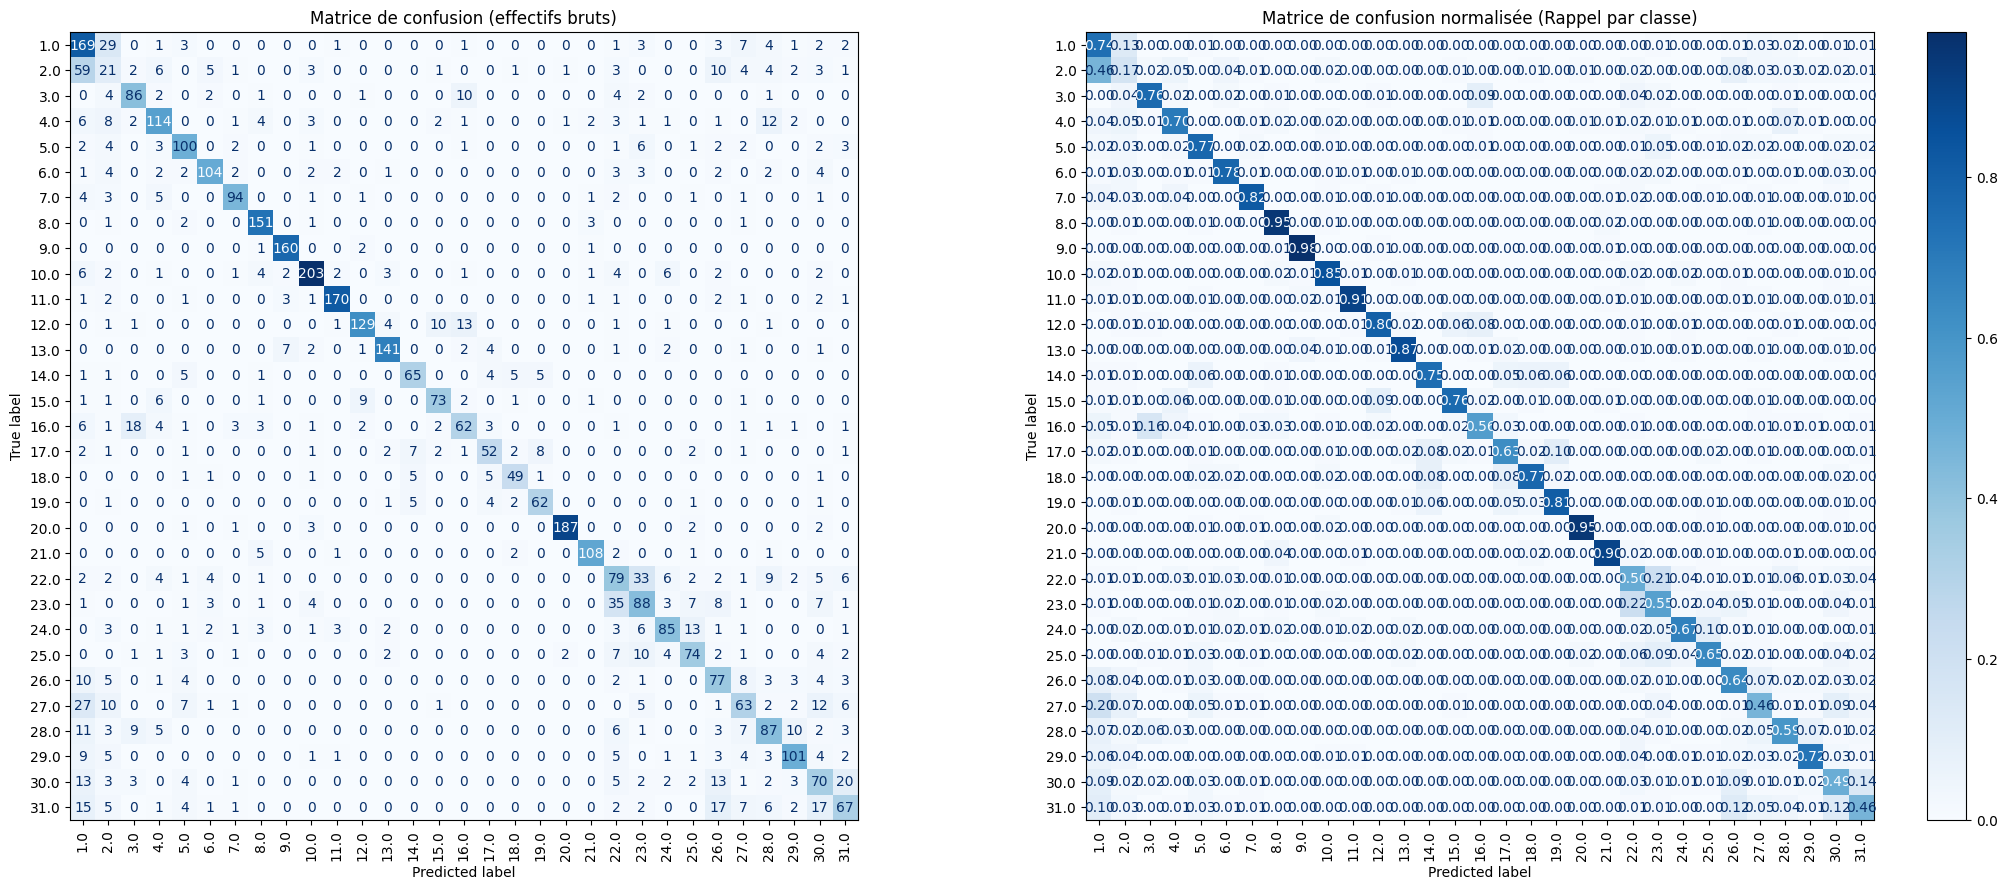

In [101]:

# ==============================================================================
# 6. MATRICE DE CONFUSION (30 × 30)
# ==============================================================================
cm = confusion_matrix(y_test, y_pred, labels=labels_idx)
cm_norm = confusion_matrix(y_test, y_pred, labels=labels_idx, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

disp_raw = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=action_names)
disp_raw.plot(ax=axes[0], cmap="Blues", xticks_rotation=90, colorbar=False, values_format="d")
axes[0].set_title("Matrice de confusion (effectifs bruts)")

disp_norm = ConfusionMatrixDisplay(confusion_matrix=np.round(cm_norm, 2), display_labels=action_names)
disp_norm.plot(ax=axes[1], cmap="Blues", xticks_rotation=90, colorbar=True, values_format=".2f")
axes[1].set_title("Matrice de confusion normalisée (Rappel par classe)")

plt.tight_layout()
plt.savefig("matrice_confusion_30_actions.png", dpi=200)
plt.show()

In [102]:
# graphe




